In [3]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler, OrdinalEncoder
from sklearn.model_selection import train_test_split
import tensorflow as tf

In [ ]:
df = pd.read_csv('dataset_mansion.csv')
df.info()
df.columns.tolist()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56231 entries, 0 to 56230
Data columns (total 18 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Unnamed: 0                           56231 non-null  int64  
 1   MTime                                56231 non-null  object 
 2   Consumption                          56231 non-null  object 
 3   Latitude                             56040 non-null  float64
 4   Longitude                            56040 non-null  float64
 5   Place                                56040 non-null  object 
 6   AirTemperature(degC)                 56023 non-null  float64
 7   HighestTemperature(degC)             56028 non-null  float64
 8   LowestTemperature(degC)              56028 non-null  float64
 9   RelativeHumidity(%)                  55942 non-null  float64
 10  WindSpeed(m/s)                       55613 non-null  float64
 11  MaximumWindSpeed(m/s)       

In [11]:
print(df["Place"].value_counts())
print(df.isnull().sum())

Place
Jyväskylä lentoasema    56040
Name: count, dtype: int64
Unnamed: 0                                 0
MTime                                      0
Consumption                                0
Latitude                                 191
Longitude                                191
Place                                    191
AirTemperature(degC)                     208
HighestTemperature(degC)                 203
LowestTemperature(degC)                  203
RelativeHumidity(%)                      289
WindSpeed(m/s)                           618
MaximumWindSpeed(m/s)                    741
MinimumWindSpeed(m/s)                    741
WindDirection(deg)                       501
PrecipitationAmount(mm)                  303
MaximumPrecipitationIntensity(mm/h)      321
AirPressure(hPa)                         210
PresentWeather(rank)                   32441
dtype: int64


In [12]:
# Fix column types that pandas misread, so the rest of the exploration is accurate:
# - 'Consumption' uses a comma as decimal separator -> loaded as text, needs to become float
# - 'MTime' is a timestamp string -> parse to datetime so we can explore the time range
df['Consumption'] = df['Consumption'].str.replace(',', '.', regex=False).astype(float)
df['MTime'] = pd.to_datetime(df['MTime'])

print(df[['MTime', 'Consumption']].dtypes)

MTime          datetime64[ns]
Consumption           float64
dtype: object


In [13]:
# Duplicate rows and the time span covered by the data
print("Duplicate rows:", df.duplicated().sum())
print("Time range:", df['MTime'].min(), "->", df['MTime'].max())
print("Rows:", len(df), " Expected hourly rows in range:",
      int((df['MTime'].max() - df['MTime'].min()).total_seconds() // 3600) + 1)

Duplicate rows: 0
Time range: 2015-12-31 22:00:00 -> 2022-05-31 20:00:00
Rows: 56231  Expected hourly rows in range: 56231


In [14]:
# Descriptive statistics
# 'Unnamed: 0' is just the original row index and 'Place' has a single constant value,
# so neither carries useful information for modelling.
df.describe()

,Unnamed: 0,MTime,Consumption,Latitude,Longitude,AirTemperature(degC),HighestTemperature(degC),LowestTemperature(degC),RelativeHumidity(%),WindSpeed(m/s),MaximumWindSpeed(m/s),MinimumWindSpeed(m/s),WindDirection(deg),PrecipitationAmount(mm),MaximumPrecipitationIntensity(mm/h),AirPressure(hPa),PresentWeather(rank)
count,56231.00000,56231,56231.000000,5.604000e+04,5.604000e+04,56023.000000,56028.000000,56028.000000,55942.000000,55613.000000,55490.000000,55490.000000,55730.000000,55928.000000,55910.000000,56021.000000,23790.000000
mean,28115.00000,2019-03-17 09:00:00,1.927321,6.239758e+01,2.567087e+01,4.250440,4.736526,3.761350,80.833882,2.755701,3.388866,2.157158,209.189521,0.068188,0.202939,1011.353658,22.453762
min,0.00000,2015-12-31 22:00:00,0.250000,6.239758e+01,2.567087e+01,-31.800000,-31.500000,-60.000000,13.000000,0.200000,0.300000,0.100000,1.000000,0.000000,0.000000,957.700000,0.000000
25%,14057.50000,2017-08-08 15:30:00,0.730000,6.239758e+01,2.567087e+01,-1.800000,-1.500000,-2.200000,71.000000,1.500000,2.000000,1.000000,142.000000,0.000000,0.000000,1003.900000,0.000000
50%,28115.00000,2019-03-17 09:00:00,1.770000,6.239758e+01,2.567087e+01,3.200000,3.600000,2.800000,88.000000,2.400000,3.000000,1.800000,203.000000,0.000000,0.000000,1011.800000,0.000000
75%,42172.50000,2020-10-23 02:30:00,2.730000,6.239758e+01,2.567087e+01,11.700000,12.300000,11.100000,96.000000,3.600000,4.300000,2.900000,296.000000,0.000000,0.000000,1019.400000,61.000000
max,56230.00000,2022-05-31 20:00:00,10.400000,6.239758e+01,2.567087e+01,32.500000,39.900000,32.100000,100.000000,15.200000,16.500000,13.000000,360.000000,15.100000,80.700000,1053.200000,87.000000
std,16232.63583,NaN,1.356188,1.421098e-14,3.552745e-15,9.886016,9.978892,9.840251,19.732548,1.693618,1.896630,1.533038,92.347150,0.337590,1.073243,12.251192,32.400488


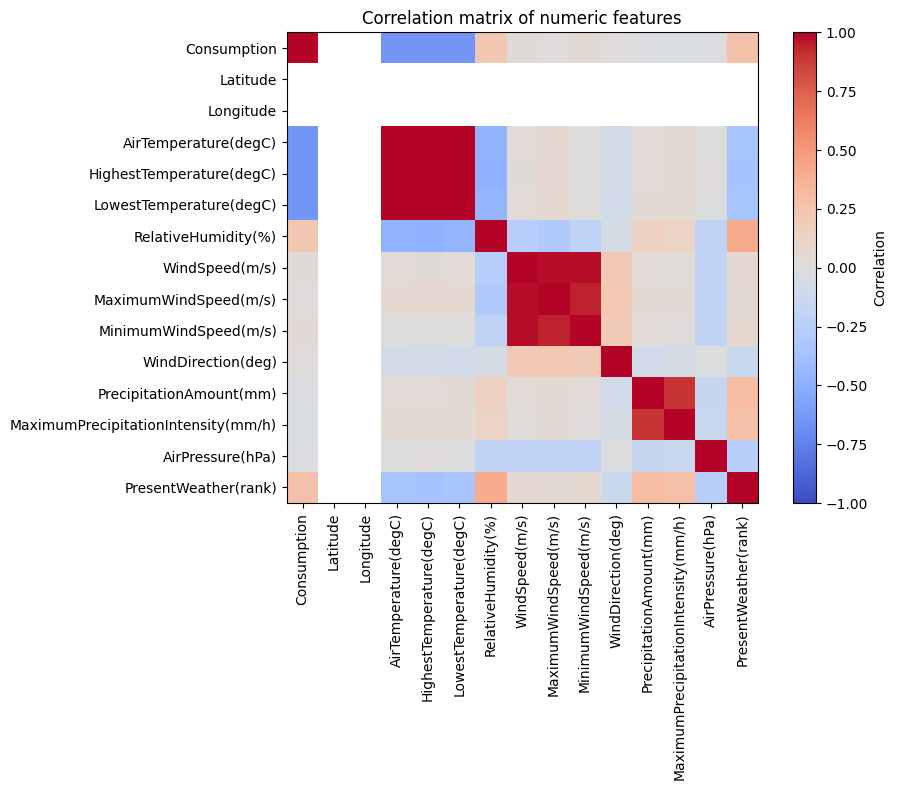

Consumption                            1.000000
PresentWeather(rank)                   0.262543
RelativeHumidity(%)                    0.225464
MinimumWindSpeed(m/s)                  0.046505
WindSpeed(m/s)                         0.028468
MaximumWindSpeed(m/s)                  0.013435
WindDirection(deg)                     0.010414
PrecipitationAmount(mm)               -0.017845
AirPressure(hPa)                      -0.019753
MaximumPrecipitationIntensity(mm/h)   -0.029924
LowestTemperature(degC)               -0.642765
AirTemperature(degC)                  -0.645008
HighestTemperature(degC)              -0.645574
Latitude                                    NaN
Longitude                                   NaN
Name: Consumption, dtype: float64


In [20]:
# Correlation between numeric features (helps spot which weather variables
# relate to Consumption and which weather columns duplicate each other)
import matplotlib.pyplot as plt

numeric_df = df.drop(columns=['Unnamed: 0']).select_dtypes(include=[np.number])
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, label='Correlation')
ax.set_title('Correlation matrix of numeric features')
plt.tight_layout()
plt.show()

print(corr['Consumption'].sort_values(ascending=False))

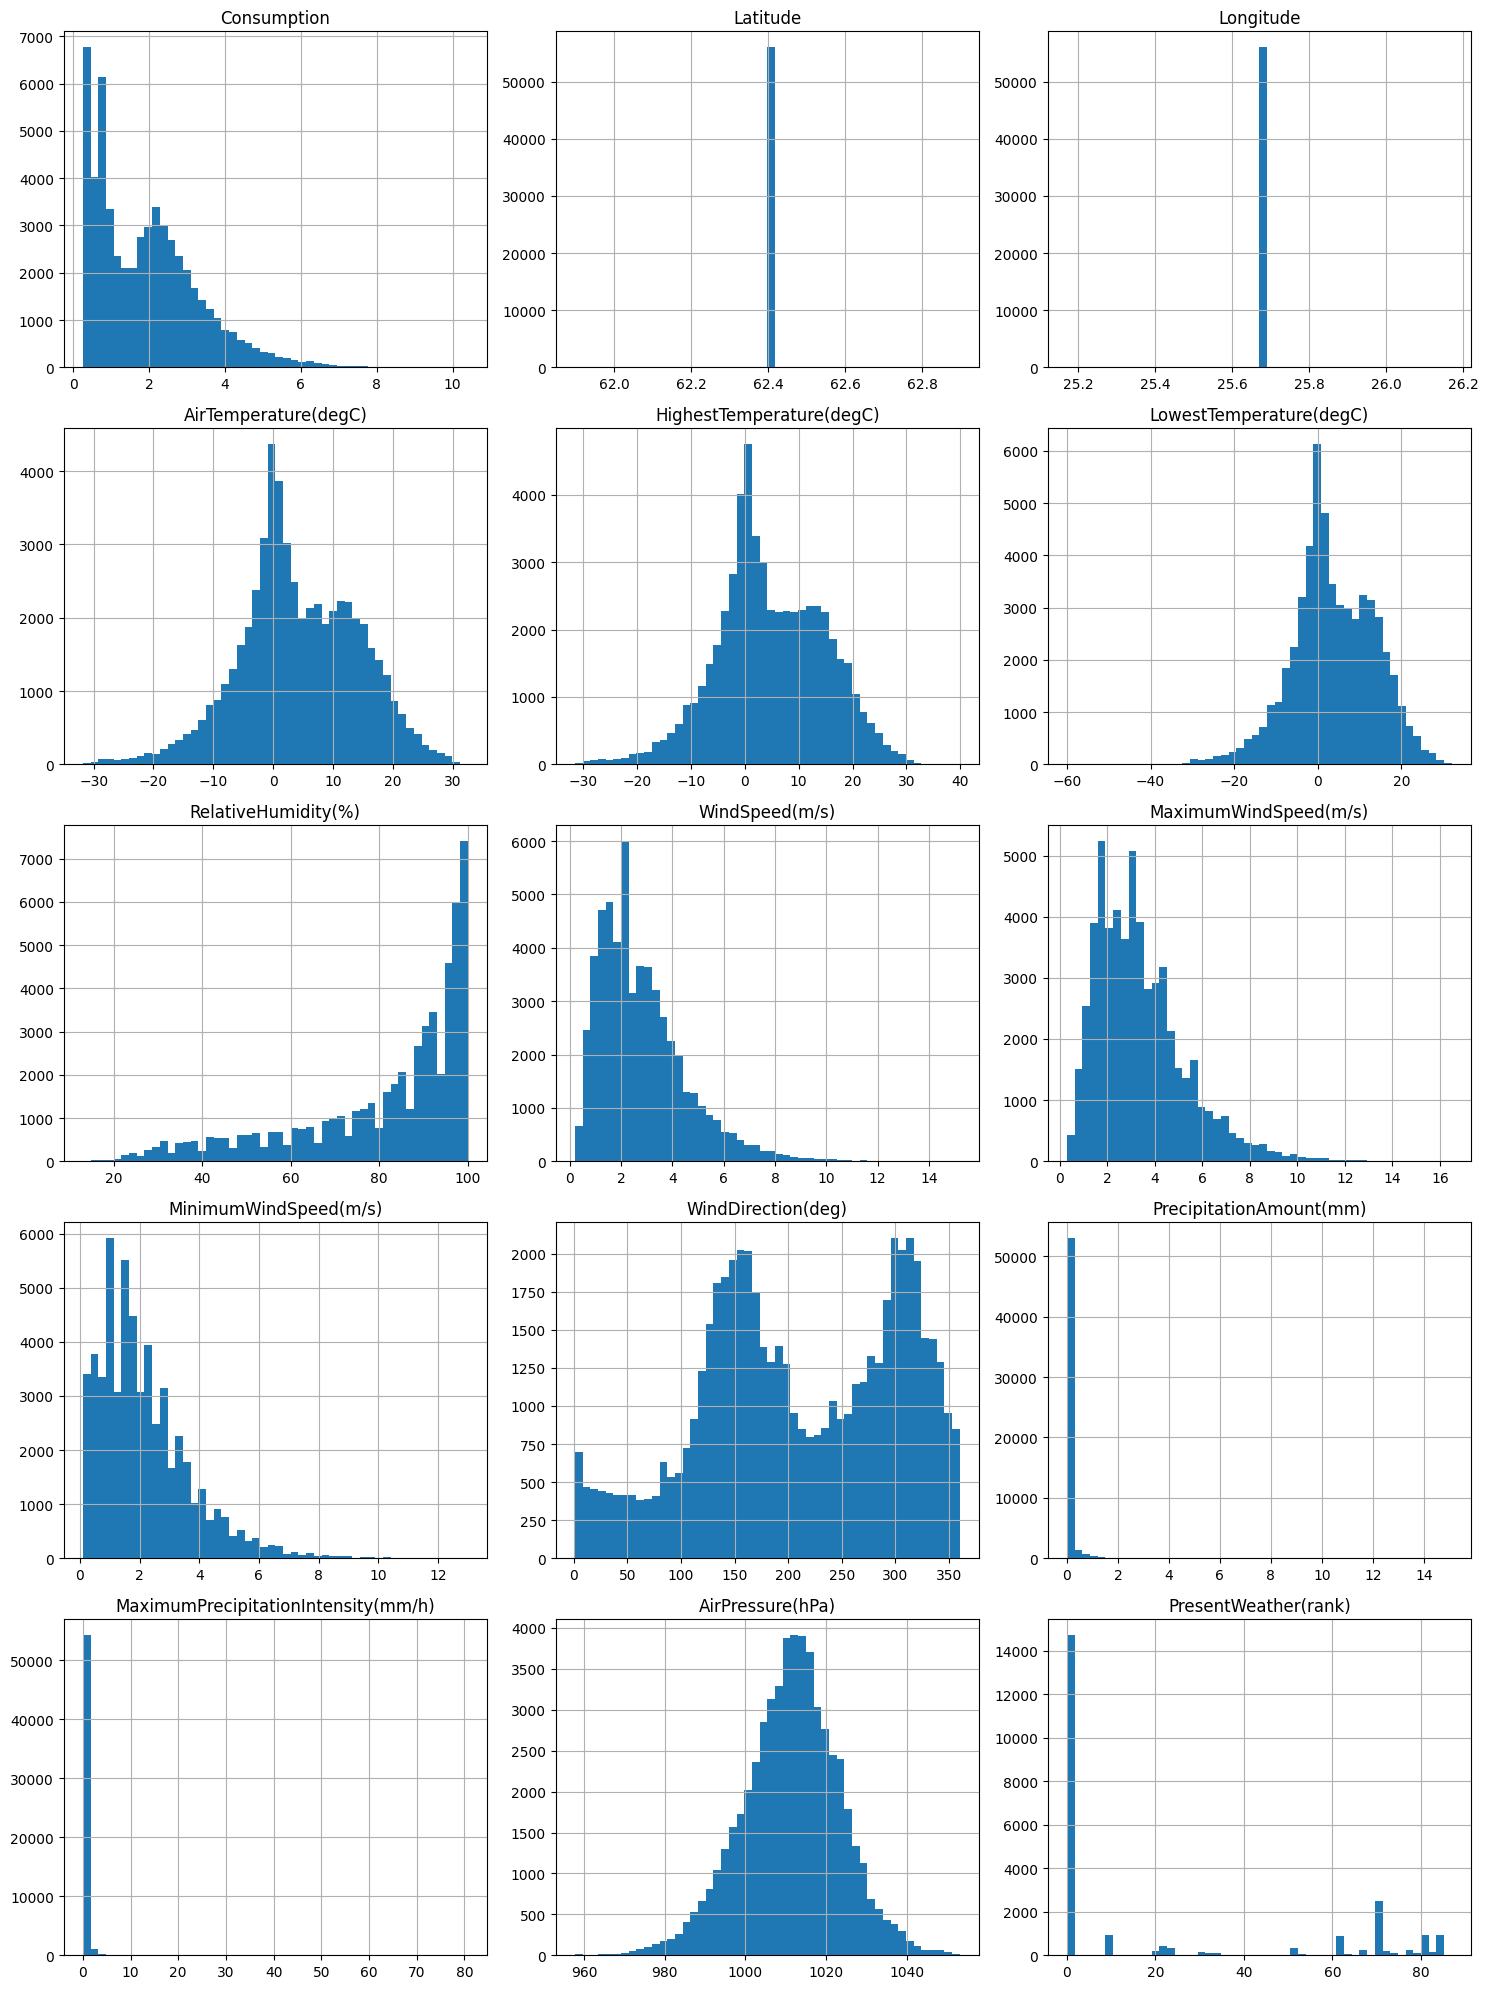

In [12]:
# Distributions of ALL numeric columns (not just a hand-picked subset)
import math

cols_to_plot = list(numeric_df.columns)  # every numeric column, incl. Latitude/Longitude/PresentWeather(rank)
ncols = 3
nrows = math.ceil(len(cols_to_plot) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
for ax, col in zip(axes.ravel(), cols_to_plot):
    df[col].hist(bins=50, ax=ax)
    ax.set_title(col)
for ax in axes.ravel()[len(cols_to_plot):]:
    ax.set_visible(False)  # hide unused subplots if the grid is larger than the column count
plt.tight_layout()
plt.show()

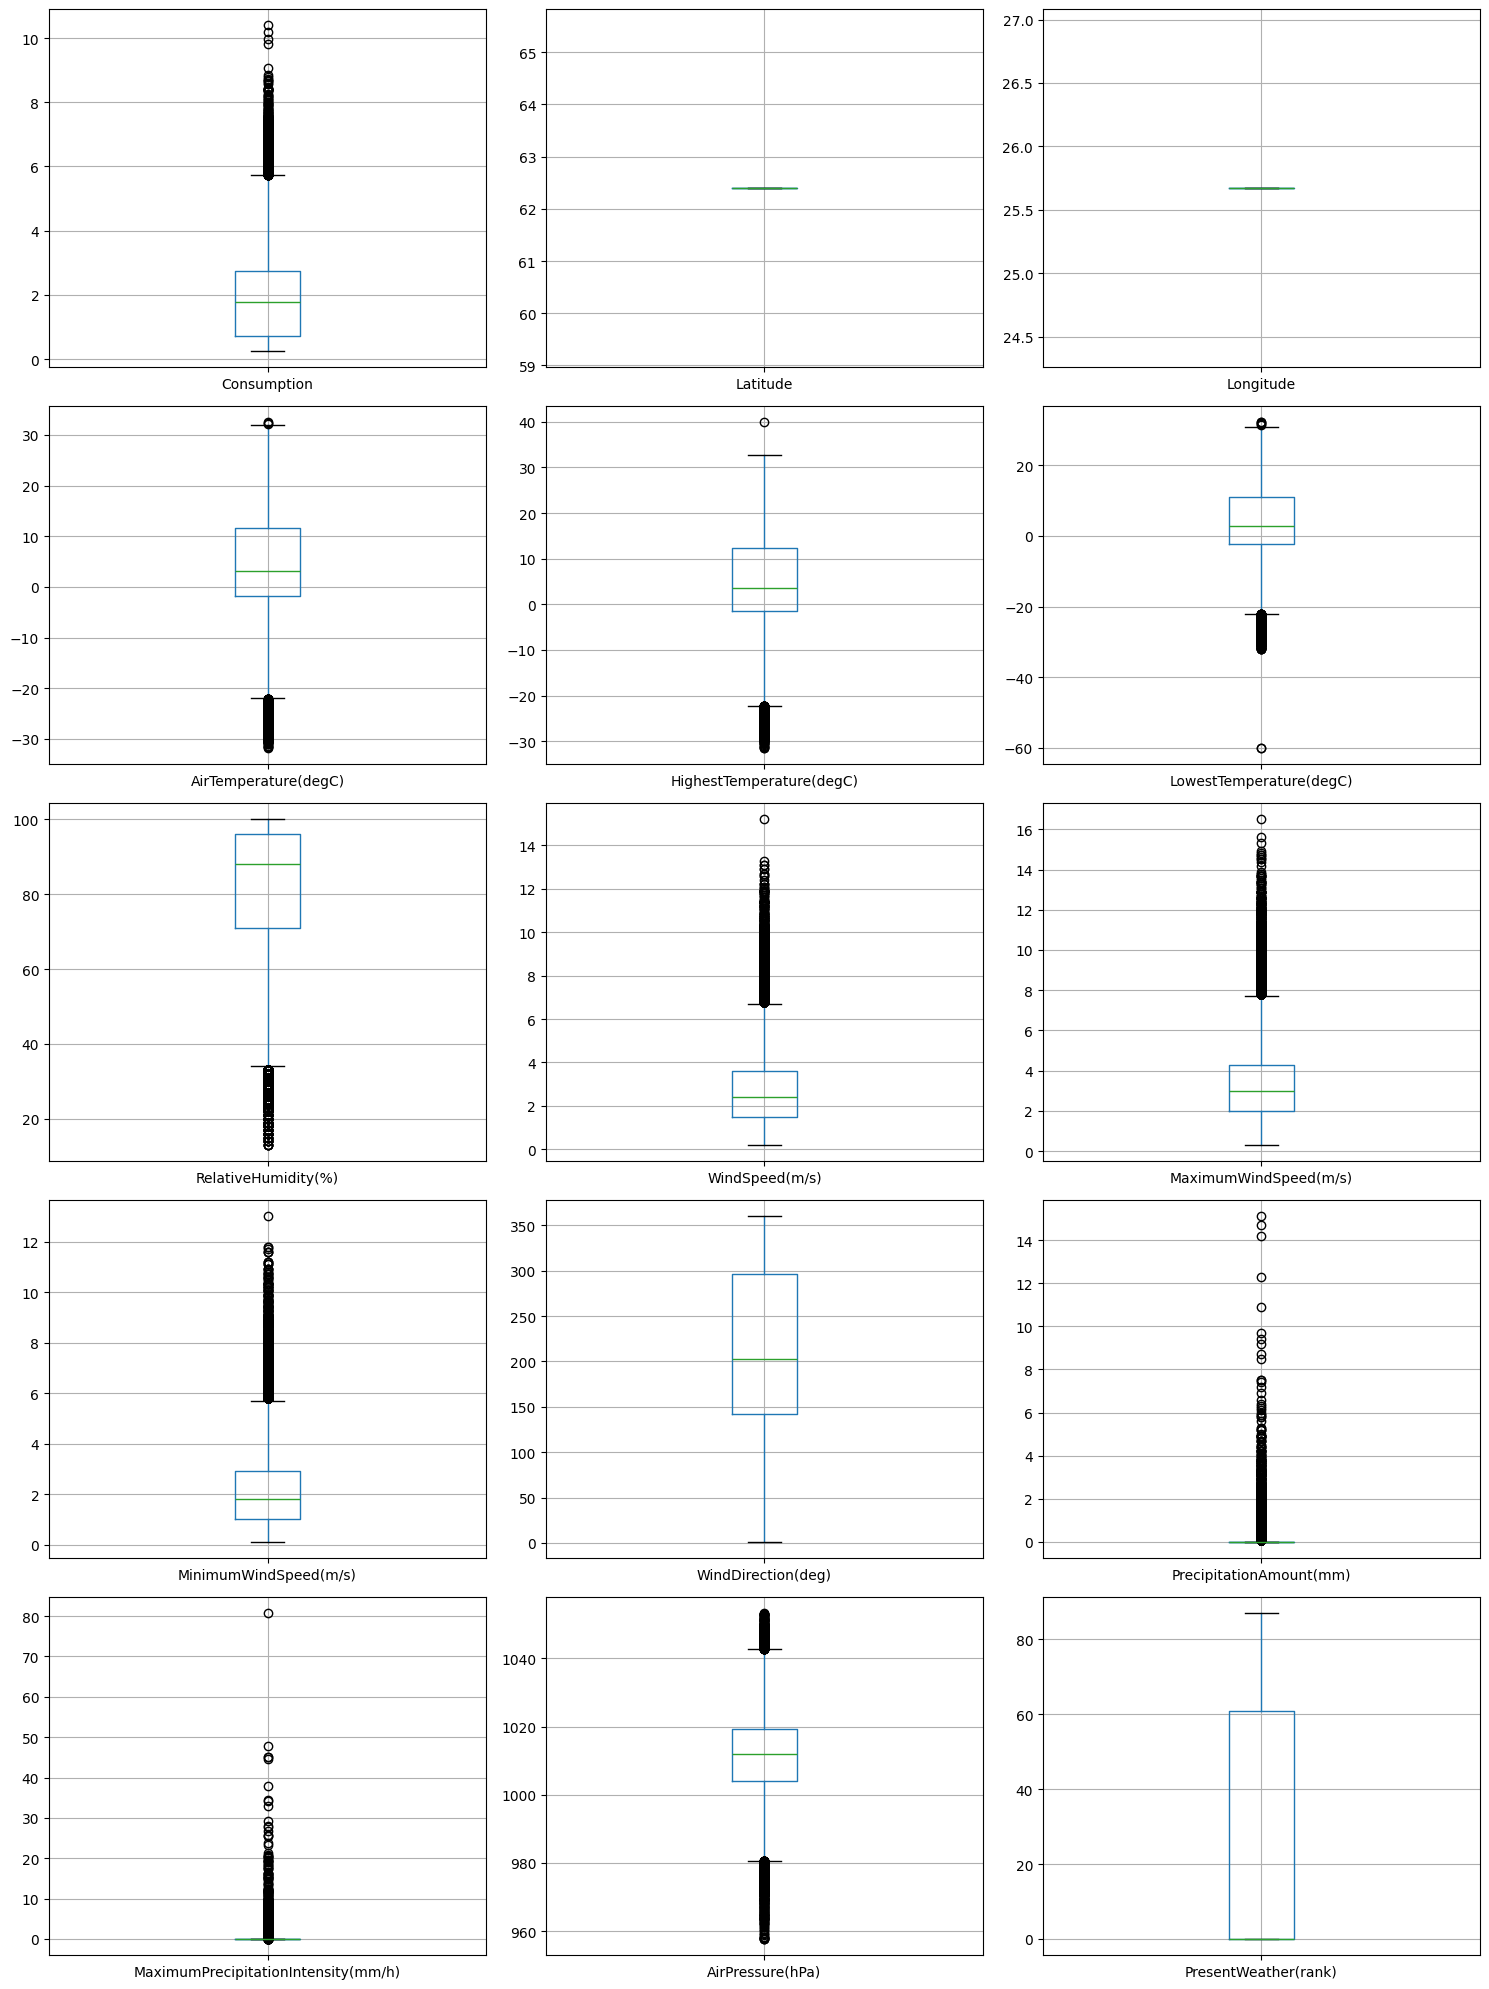

Consumption: 744 potential outliers (outside [-2.27, 5.73])
Latitude: 0 potential outliers (outside [62.40, 62.40])
Longitude: 0 potential outliers (outside [25.67, 25.67])
AirTemperature(degC): 466 potential outliers (outside [-22.05, 31.95])
HighestTemperature(degC): 386 potential outliers (outside [-22.20, 33.00])
LowestTemperature(degC): 558 potential outliers (outside [-22.15, 31.05])
RelativeHumidity(%): 1850 potential outliers (outside [33.50, 133.50])
WindSpeed(m/s): 1659 potential outliers (outside [-1.65, 6.75])
MaximumWindSpeed(m/s): 1741 potential outliers (outside [-1.45, 7.75])
MinimumWindSpeed(m/s): 1739 potential outliers (outside [-1.85, 5.75])
WindDirection(deg): 0 potential outliers (outside [-89.00, 527.00])
PrecipitationAmount(mm): 7542 potential outliers (outside [0.00, 0.00])
MaximumPrecipitationIntensity(mm/h): 7965 potential outliers (outside [0.00, 0.00])
AirPressure(hPa): 943 potential outliers (outside [980.65, 1042.65])
PresentWeather(rank): 0 potential out

In [13]:
# Outlier check via boxplots + IQR rule for ALL numeric columns
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
for ax, col in zip(axes.ravel(), cols_to_plot):
    df.boxplot(column=col, ax=ax)
for ax in axes.ravel()[len(cols_to_plot):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

for col in cols_to_plot:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {n_outliers} potential outliers (outside [{lower:.2f}, {upper:.2f}])")